# 5.4 Corner column A1: biaxial bending

Both edge beams frame into the corner column, so it bends about both axes.

In [1]:
import sys; sys.path.insert(0, '..')
from ec2.setup import *

## Method (EC2 5.8.9)

Separate design in each direction first. Biaxial bending may be ignored if the slenderness ratios differ by no more than a factor of 2 **and** the relative eccentricities satisfy $e_y/h_{eq}\div e_z/b_{eq}\le0.2$ (or the inverse). Otherwise:

$$\left(\frac{M_{Edz}}{M_{Rdz}}\right)^a+\left(\frac{M_{Edy}}{M_{Rdy}}\right)^a\le1.0$$

| N<sub>Ed</sub>/N<sub>Rd</sub> | 0.1 | 0.7 | 1.0 |
|:--|:-:|:-:|:-:|
| a (rectangular) | 1.0 | 1.5 | 2.0 |

### Input guide

| Name | Meaning | Unit | Expected |
|:--|:--|:--|:--|
| `phi` | Main bar; 8 bars, fixed layout | mm | 12, 16, 20, 25, 32 |
| `link`, `s_link` | Link size and spacing | mm |  |

Column size, loads and materials come from `BRIEF`: see the guide in Notebook 0.1. Keep the column square.

In [2]:
# INPUTS: edit only this cell, then run the cells below it
# Size, loads and materials come from BRIEF in ec2/project.py. Layout: 8 bars (4 corners, 4 mid-faces)
phi, link, s_link = 16, 8, 300      # main bar (mm), link (mm), link spacing (mm)

In [3]:
def direction(s, axis, N, M, kb_sum, b, h, As, qp):
    """Design moment in one direction (first order, plus second order if slender). qp = quasi-permanent / ULS load ratio."""
    s.let("M_top", M, "kN·m", f"First-order moment at the top, {axis}", "BS 8110-1 3.2.1.2.5")
    s.let("k_c", b * h**3 / 12 / (BRIEF["storey"] * 1e3) / 1e3, "10³ mm³", "I/l of each column"); s.let("k_b", kb_sum, "10³ mm³", "Sum of I/l of the beams (rectangular gross section, conservative)")
    s.calc("k1", "max(2*k_c/(2*k_b), 0.1)", "", "EC2 5.8.3.2(3), (4)", "Top: columns above and below, beams at 2EI/l")
    s.let("l", BRIEF["storey"] - BRIEF["beam"][1] / 1000, "m", "Clear height")
    s.calc("l0", "0.5*l*sqrt((1 + k1/(0.45 + k1))*2)", "m", "EC2 Exp. (5.15), k₂ = ∞", "Base taken as pinned (upper bound: the bracket tends to 2)")
    s.let("N_Ed", N, "kN"); s.let("h", h, "mm"); s.let("b", b, "mm")
    C.imperfection(s)
    s.calc("M_02", "M_top + N_Ed*e_i/1000", "kN·m", "EC2 5.2(7)", "Larger end, with imperfection"); s.calc("M_01", "N_Ed*e_i/1000", "kN·m", "EC2 5.2(7)", "Smaller end: pinned base, imperfection only")
    slender = C.slenderness(s, s["l"], h, N, b, s["M_01"], s["M_02"], l0=s["l0"], As=As)
    if slender:
        C.creep(s, b, h, BRIEF["RH"], BRIEF["t0"])
        s.let("i_s", math.sqrt(6 * (h / 2 - s["d_c"]) ** 2 / 8), "mm", "Radius of gyration of the 8 bars", "EC2 5.8.8.3(2)"); s.calc("d", "h/2 + i_s", "mm", "EC2 5.8.8.3(2)")
        C.second_order(s, s["d"], qp)
        s.calc("M_Ed", "max(M_02, M_0e + M_2, M_01 + 0.5*M_2, M_min)", "kN·m", "EC2 5.8.8.2, 6.1(4); BS 8110-1 3.8.3.2", f"Design moment with second-order effects, {axis}")
    else:
        s.calc("M_Ed", "max(M_02, M_min)", "kN·m", "EC2 5.8.8.1, 6.1(4)", f"Design moment, {axis}")
    return s["M_Ed"]

b, h = BRIEF["col"]
I_b = BRIEF["beam"][0] * BRIEF["beam"][1] ** 3 / 12 / 1e3          # 10^3 mm3 x mm
kbeam = lambda ln: I_b / ((BRIEF["lx_bay"] if ln in "AB" else BRIEF["ly_bay"]) * 1e3)

def section(s, N):
    """Cover, bars, limits, links, interaction curve for the 8-bar column."""
    c = D.cover(s, BRIEF["exposure"], phi, link)
    s.let("N_Ed", N, "kN"); s.let("A_c", b * h, "mm²"); s.let("phi_min", BRIEF["ndp"]["phi_col_min"], "mm", "Minimum bar", "EC2 9.5.2(1), NA"); s.check("phi", ">=", "phi_min", "minimum bar diameter", "EC2 9.5.2(1)")
    s.calc("A_s_min", "max(0.10*N_Ed*1000/f_yd, 0.002*A_c)", "mm²", "EC2 Exp. (9.12N)"); s.calc("A_s_max", "0.04*A_c", "mm²", "EC2 9.5.2(3)")
    s.calc("A_s", "8*pi*phi**2/4", "mm²", "", f"8H{phi}: one at each corner, one at the middle of each face"); s.check("A_s", ">=", "A_s_min", "minimum steel", "EC2 9.5.2(2)"); s.check("A_s", "<=", "A_s_max", "maximum steel", "EC2 9.5.2(3)")
    s.calc("d_c", "c_nom + phi_link + phi/2", "mm", "", "Bar centre from the face"); s.show("Reinforcement")
    C.links(s, phi, phi, b, h, link, s_link, 3, 3, c); s.show("Links")
    cur = C.interaction(b, h, C.perimeter_layers(3, 3, phi, b, h, s["d_c"]), s["f_cd"], s["f_yd"])
    return c, cur

In [4]:
t = PJ.takedown("A1"); N = 1.35 * t["G"] + 1.5 * t["Q"]; qp = (t["G"] + PSI[BRIEF["category"]][2] * t["Q"]) / N; Nmin = t["G"]
s = Sheet("Column A1", element="Column A1, ground storey")
D.materials(s, BRIEF["fck"], BRIEF["fyk"], BRIEF["ndp"]); c, cur = section(s, N); As = s["A_s"]
Mx = direction(s, "bending with Beam A", N, PJ.column_joint("A", 0)["M"], kbeam("A"), b, h, As, qp); lamx, M02x = s["lam"], s["M_02"]; s.show("Direction x (Beam A)")
My = direction(s, "bending with Beam 1", N, PJ.column_joint("1", 0)["M"], kbeam("1"), b, h, As, qp); lamy, M02y = s["lam"], s["M_02"]; s.show("Direction y (Beam 1)")

## Column A1

*Project:* EC2 design guide &nbsp;|&nbsp; *Element:* Column A1, ground storey

### Materials

| Reference | Calculation | Output |
|:--|:--|:--|
| EC2 Table 3.1 | Concrete cylinder strength (project input): $f_{ck}$ | $f_{ck} = 30$ N/mm²<br><small>(= 30 MPa)</small> |
| EC2 3.2.2(3) | Steel yield strength (project input): $f_{yk}$ | $f_{yk} = 500$ N/mm²<br><small>(= 500 MPa)</small> |
| EC2 2.4.2.4, Table 2.1N | Partial factor, concrete: $\gamma_{c}$ | $\gamma_{c} = 1.5$  |
| EC2 2.4.2.4, Table 2.1N | Partial factor, reinforcement: $\gamma_{s}$ | $\gamma_{s} = 1.15$  |
| EC2 3.1.6(1), NA | Flexure and axial load (UK National Annex): $\alpha_{cc}$ | $\alpha_{cc} = 0.85$  |
| EC2 Exp. (3.15) | $f_{cd} = \dfrac{\alpha_{cc}\,f_{ck}}{\gamma_{c}}$<br>$\quad = \dfrac{0.85\times 30}{1.5}$ | $\mathbf{f_{cd} = 17}$ N/mm²<br><small>(= 17 MPa)</small> |
| EC2 3.2.7, Fig. 3.8 | $f_{yd} = \dfrac{f_{yk}}{\gamma_{s}}$<br>$\quad = \dfrac{500}{1.15}$ | $\mathbf{f_{yd} = 434.8}$ N/mm²<br><small>(= 434.8 MPa)</small> |
| EC2 Table 3.1 | $f_{ctm} = 0.3\,f_{ck}^{2/3}$<br>$\quad = 0.3\times 30^{2/3}$ | $\mathbf{f_{ctm} = 2.896}$ N/mm²<br><small>(= 2.896 MPa)</small> |
| EC2 3.2.7(4) | Steel modulus: $E_{s}$ | $E_{s} = 200000$ N/mm²<br><small>(= 200000 MPa)</small> |


### Durability – nominal cover

| Reference | Calculation | Output |
|:--|:--|:--|
|  | Main bar diameter: $\phi$ | $\phi = 16$ mm |
| EC2 Table 4.1, 4.4N | Exposure XC1, class S4: $c_{min,dur}$ | $c_{min,dur} = 15$ mm |
| EC2 4.4.1.3(1) | Allowance for deviation: $\Delta c_{dev}$ | $\Delta c_{dev} = 10$ mm |
|  | Link diameter: $\phi_{link}$ | $\phi_{link} = 8$ mm |
| EC2 Exp. (4.1), (4.2) | To the link<br>$c_{nom,link} = \max\left\{\phi_{link};\; c_{min,dur};\; 10\right\} + \Delta c_{dev}$<br>$\quad = \max\left\{8;\; 15;\; 10\right\} + 10$ | $\mathbf{c_{nom,link} = 25}$ mm |
| EC2 Exp. (4.1), (4.2) | To the link, so that the main bar complies<br>$c_{nom,bar} = \max\left\{\phi;\; c_{min,dur};\; 10\right\} + \Delta c_{dev} - \phi_{link}$<br>$\quad = \max\left\{16;\; 15;\; 10\right\} + 10 - 8$ | $\mathbf{c_{nom,bar} = 18}$ mm |
|  | $c_{req} = \max\left\{c_{nom,link};\; c_{nom,bar}\right\}$<br>$\quad = \max\left\{25;\; 18\right\}$ | $\mathbf{c_{req} = 25}$ mm |
|  | Cover adopted: $c_{nom}$ | $c_{nom} = 25$ mm |
| EC2 4.4.1 | **Check:** nominal cover<br>$c_{nom} = 25 \ge c_{req} = 25$ mm | ✅ **PASS**<br>ratio 1.00 |
| NA to EC2, 4.4.1.2(5) | UK projects: confirm concrete quality and cover against BS 8500-1 Tables A.4/A.5 as the UK NA requires. |  |


### Reinforcement

| Reference | Calculation | Output |
|:--|:--|:--|
|  | $N_{Ed}$ | $N_{Ed} = 414.7$ kN |
|  | $A_{c}$ | $A_{c} = 122500$ mm² |
| EC2 9.5.2(1), NA | Minimum bar: $\phi_{min}$ | $\phi_{min} = 12$ mm |
| EC2 9.5.2(1) | **Check:** minimum bar diameter<br>$\phi = 16 \ge \phi_{min} = 12$ mm | ✅ **PASS**<br>ratio 0.75 |
| EC2 Exp. (9.12N) | $A_{s,min} = \max\left\{\dfrac{0.1\,N_{Ed}\times 1000}{f_{yd}};\; 0.002\,A_{c}\right\}$<br>$\quad = \max\left\{\dfrac{0.1\times 414.7\times 1000}{434.8};\; 0.002\times 122500\right\}$ | $\mathbf{A_{s,min} = 245}$ mm² |
| EC2 9.5.2(3) | $A_{s,max} = 0.04\,A_{c}$<br>$\quad = 0.04\times 122500$ | $\mathbf{A_{s,max} = 4900}$ mm² |
|  | 8H16: one at each corner, one at the middle of each face<br>$A_{s} = \dfrac{8\,\pi\,\phi^{2}}{4}$<br>$\quad = \dfrac{8\times \pi\times 16^{2}}{4}$ | $\mathbf{A_{s} = 1608.5}$ mm² |
| EC2 9.5.2(2) | **Check:** minimum steel<br>$A_{s} = 1608.5 \ge A_{s,min} = 245$ mm² | ✅ **PASS**<br>ratio 0.15 |
| EC2 9.5.2(3) | **Check:** maximum steel<br>$A_{s} = 1608.5 \le A_{s,max} = 4900$ mm² | ✅ **PASS**<br>ratio 0.33 |
|  | Bar centre from the face<br>$d_{c} = c_{nom} + \phi_{link} + \dfrac{\phi}{2}$<br>$\quad = 25 + 8 + \dfrac{16}{2}$ | $\mathbf{d_{c} = 41}$ mm |


### Links

| Reference | Calculation | Output |
|:--|:--|:--|
| EC2 9.5.3(1) | $\phi_{link,min} = \max\left\{6;\; \dfrac{16}{4}\right\}$<br>$\quad = \max\left\{6;\; \dfrac{16}{4}\right\}$ | $\mathbf{\phi_{link,min} = 6}$ mm |
| EC2 9.5.3(1) | **Check:** link diameter<br>$\phi_{link} = 8 \ge \phi_{link,min} = 6$ mm | ✅ **PASS**<br>ratio 0.75 |
| EC2 9.5.3(3), NA | min(20 φ_min, smaller side, 400): $s_{cl,max}$ | $s_{cl,max} = 320$ mm |
|  | Link spacing: $s_{link}$ | $s_{link} = 300$ mm |
| EC2 9.5.3(3) | **Check:** link spacing<br>$s_{link} = 300 \le s_{cl,max} = 320$ mm | ✅ **PASS**<br>ratio 0.94 |
| EC2 9.5.3(4) | Within 350 mm above/below a beam or slab, and at laps of bars > 14 mm<br>$s_{cl,red} = 0.6\,s_{cl,max}$<br>$\quad = 0.6\times 320$ | $\mathbf{s_{cl,red} = 192}$ mm |
|  | **PROVIDE: H8 links @ 300 mm; @ 175 mm near beams, slabs and laps** | 🟦 **H8 links @ 300 mm; @ 175 mm near beams, slabs and laps** |
|  | Distance from an intermediate bar to the restrained corner bar (centres): $s_{face}$ | $s_{face} = 134$ mm |
| EC2 9.5.3(6) | **Check:** bar within 150 mm of a restrained bar, else add cross-ties<br>$s_{face} = 134 \le 150$ mm | ✅ **PASS**<br>ratio 0.89 |


### Direction x (Beam A)

| Reference | Calculation | Output |
|:--|:--|:--|
| BS 8110-1 3.2.1.2.5 | First-order moment at the top, bending with Beam A: $M_{top}$ | $M_{top} = 30.15$ kN·m |
|  | I/l of each column: $k_{c}$ | $k_{c} = 357.3$ 10³ mm³ |
|  | Sum of I/l of the beams (rectangular gross section, conservative): $k_{b}$ | $k_{b} = 520.8$ 10³ mm³ |
| EC2 5.8.3.2(3), (4) | Top: columns above and below, beams at 2EI/l<br>$k_{1} = \max\left\{\dfrac{2\,k_{c}}{2\,k_{b}};\; 0.1\right\}$<br>$\quad = \max\left\{\dfrac{2\times 357.3}{2\times 520.8};\; 0.1\right\}$ | $\mathbf{k_{1} = 0.686}$ |
|  | Clear height: $l$ | $l = 3$ m |
| EC2 Exp. (5.15), k₂ = ∞ | Base taken as pinned (upper bound: the bracket tends to 2)<br>$l_{0} = 0.5\,l\,\sqrt{\left(1 + \dfrac{k_{1}}{0.45 + k_{1}}\right)\times 2}$<br>$\quad = 0.5\times 3\times \sqrt{\left(1 + \dfrac{0.686}{0.45 + 0.686}\right)\times 2}$ | $\mathbf{l_{0} = 2.687}$ m |
|  | $h$ | $h = 350$ mm |
|  | $b$ | $b = 350$ mm |
| EC2 5.2(7), 5.2(9) – braced | Imperfection eccentricity<br>$e_{i} = \dfrac{l_{0}\times 1000}{400}$<br>$\quad = \dfrac{2.687\times 1000}{400}$ | $\mathbf{e_{i} = 6.716}$ mm |
| EC2 6.1(4) | Minimum eccentricity<br>$e_{0} = \max\left\{\dfrac{h}{30};\; 20\right\}$<br>$\quad = \max\left\{\dfrac{350}{30};\; 20\right\}$ | $\mathbf{e_{0} = 20}$ mm |
| EC2 6.1(4) | $M_{min} = \dfrac{N_{Ed}\,e_{0}}{1000}$<br>$\quad = \dfrac{414.7\times 20}{1000}$ | $\mathbf{M_{min} = 8.294}$ kN·m |
| EC2 5.2(7) | Larger end, with imperfection<br>$M_{02} = M_{top} + \dfrac{N_{Ed}\,e_{i}}{1000}$<br>$\quad = 30.15 + \dfrac{414.7\times 6.716}{1000}$ | $\mathbf{M_{02} = 32.93}$ kN·m |
| EC2 5.2(7) | Smaller end: pinned base, imperfection only<br>$M_{01} = \dfrac{N_{Ed}\,e_{i}}{1000}$<br>$\quad = \dfrac{414.7\times 6.716}{1000}$ | $\mathbf{M_{01} = 2.785}$ kN·m |
| EC2 5.8.3.2(1) | Radius of gyration, rectangle<br>$i = \dfrac{h}{\sqrt{12}}$<br>$\quad = \dfrac{350}{\sqrt{12}}$ | $\mathbf{i = 101}$ mm |
| EC2 Exp. (5.14) | $\lambda = \dfrac{l_{0}\times 1000}{i}$<br>$\quad = \dfrac{2.687\times 1000}{101}$ | $\mathbf{\lambda = 26.59}$ |
| EC2 5.8.3.1 | $n = \dfrac{N_{Ed}\times 1000}{b\,h\,f_{cd}}$<br>$\quad = \dfrac{414.7\times 1000}{350\times 350\times 17}$ | $\mathbf{n = 0.199}$ |
| EC2 5.8.3.1(1) | Creep ratio not used: default: $A$ | $A = 0.7$  |
| EC2 5.8.3.1(1) | $\omega = \dfrac{A_{s}\,f_{yd}}{b\,h\,f_{cd}}$<br>$\quad = \dfrac{1608.5\times 434.8}{350\times 350\times 17}$ | $\mathbf{\omega = 0.336}$ |
| EC2 5.8.3.1(1) | $B = \sqrt{1 + 2\,\omega}$<br>$\quad = \sqrt{1 + 2\times 0.336}$ | $\mathbf{B = 1.293}$ |
| EC2 5.8.3.1(1) | $r_{m} = \dfrac{M_{01}}{M_{02}}$<br>$\quad = \dfrac{2.785}{32.93}$ | $\mathbf{r_{m} = 0.08457}$ |
| EC2 5.8.3.1(1) | $C = 1.7 - r_{m}$<br>$\quad = 1.7 - 0.08457$ | $\mathbf{C = 1.615}$ |
| EC2 Exp. (5.13N), NA | $\lambda_{lim} = \dfrac{20\,A\,B\,C}{\sqrt{n}}$<br>$\quad = \dfrac{20\times 0.7\times 1.293\times 1.615}{\sqrt{0.199}}$ | $\mathbf{\lambda_{lim} = 65.53}$ |
| EC2 5.8.3.1 | λ ≤ λ<sub>lim</sub> → the column is **STOCKY (short)** : second-order effects may be ignored. |  |
| EC2 5.8.8.1, 6.1(4) | Design moment, bending with Beam A<br>$M_{Ed} = \max\left\{M_{02};\; M_{min}\right\}$<br>$\quad = \max\left\{32.93;\; 8.294\right\}$ | $\mathbf{M_{Ed} = 32.93}$ kN·m |


### Direction y (Beam 1)

| Reference | Calculation | Output |
|:--|:--|:--|
| BS 8110-1 3.2.1.2.5 | First-order moment at the top, bending with Beam 1: $M_{top}$ | $M_{top} = 17.86$ kN·m |
|  | Sum of I/l of the beams (rectangular gross section, conservative): $k_{b}$ | $k_{b} = 625$ 10³ mm³ |
| EC2 5.8.3.2(3), (4) | Top: columns above and below, beams at 2EI/l<br>$k_{1} = \max\left\{\dfrac{2\,k_{c}}{2\,k_{b}};\; 0.1\right\}$<br>$\quad = \max\left\{\dfrac{2\times 357.3}{2\times 625};\; 0.1\right\}$ | $\mathbf{k_{1} = 0.572}$ |
| EC2 Exp. (5.15), k₂ = ∞ | Base taken as pinned (upper bound: the bracket tends to 2)<br>$l_{0} = 0.5\,l\,\sqrt{\left(1 + \dfrac{k_{1}}{0.45 + k_{1}}\right)\times 2}$<br>$\quad = 0.5\times 3\times \sqrt{\left(1 + \dfrac{0.572}{0.45 + 0.572}\right)\times 2}$ | $\mathbf{l_{0} = 2.649}$ m |
| EC2 5.2(7), 5.2(9) – braced | Imperfection eccentricity<br>$e_{i} = \dfrac{l_{0}\times 1000}{400}$<br>$\quad = \dfrac{2.649\times 1000}{400}$ | $\mathbf{e_{i} = 6.623}$ mm |
| EC2 5.2(7) | Larger end, with imperfection<br>$M_{02} = M_{top} + \dfrac{N_{Ed}\,e_{i}}{1000}$<br>$\quad = 17.86 + \dfrac{414.7\times 6.623}{1000}$ | $\mathbf{M_{02} = 20.61}$ kN·m |
| EC2 5.2(7) | Smaller end: pinned base, imperfection only<br>$M_{01} = \dfrac{N_{Ed}\,e_{i}}{1000}$<br>$\quad = \dfrac{414.7\times 6.623}{1000}$ | $\mathbf{M_{01} = 2.746}$ kN·m |
| EC2 Exp. (5.14) | $\lambda = \dfrac{l_{0}\times 1000}{i}$<br>$\quad = \dfrac{2.649\times 1000}{101}$ | $\mathbf{\lambda = 26.22}$ |
| EC2 5.8.3.1(1) | $r_{m} = \dfrac{M_{01}}{M_{02}}$<br>$\quad = \dfrac{2.746}{20.61}$ | $\mathbf{r_{m} = 0.133}$ |
| EC2 5.8.3.1(1) | $C = 1.7 - r_{m}$<br>$\quad = 1.7 - 0.133$ | $\mathbf{C = 1.567}$ |
| EC2 Exp. (5.13N), NA | $\lambda_{lim} = \dfrac{20\,A\,B\,C}{\sqrt{n}}$<br>$\quad = \dfrac{20\times 0.7\times 1.293\times 1.567}{\sqrt{0.199}}$ | $\mathbf{\lambda_{lim} = 63.55}$ |
| EC2 5.8.3.1 | λ ≤ λ<sub>lim</sub> → the column is **STOCKY (short)** : second-order effects may be ignored. |  |
| EC2 5.8.8.1, 6.1(4) | Design moment, bending with Beam 1<br>$M_{Ed} = \max\left\{M_{02};\; M_{min}\right\}$<br>$\quad = \max\left\{20.61;\; 8.294\right\}$ | $\mathbf{M_{Ed} = 20.61}$ kN·m |


## Is the biaxial check needed?

In [5]:
s.let("lam_x", lamx); s.let("lam_y", lamy); s.let("M_Ed_x", Mx, "kN·m"); s.let("M_Ed_y", My, "kN·m")
s.calc("r_lam", "max(lam_x/lam_y, lam_y/lam_x)", "", "EC2 Exp. (5.38a)"); s.calc("r_e", "min(M_Ed_x/M_Ed_y, M_Ed_y/M_Ed_x)", "", "EC2 Exp. (5.38b), square section", "Ratio of the relative eccentricities")
s.note(f"r_λ = {s['r_lam']:.2f} (limit 2) and the eccentricity ratio is {s['r_e']:.2f} (limit 0.2): " + ("biaxial check not required." if s["r_lam"] <= 2 and s["r_e"] <= .2 else "**biaxial check required.**"), "EC2 5.8.9(3)"); s.show()

| Reference | Calculation | Output |
|:--|:--|:--|
|  | $\lambda_{x}$ | $\lambda_{x} = 26.59$  |
|  | $\lambda_{y}$ | $\lambda_{y} = 26.22$  |
|  | $M_{Ed,x}$ | $M_{Ed,x} = 32.93$ kN·m |
|  | $M_{Ed,y}$ | $M_{Ed,y} = 20.61$ kN·m |
| EC2 Exp. (5.38a) | $r_{\lambda} = \max\left\{\dfrac{\lambda_{x}}{\lambda_{y}};\; \dfrac{\lambda_{y}}{\lambda_{x}}\right\}$<br>$\quad = \max\left\{\dfrac{26.59}{26.22};\; \dfrac{26.22}{26.59}\right\}$ | $\mathbf{r_{\lambda} = 1.014}$ |
| EC2 Exp. (5.38b), square section | Ratio of the relative eccentricities<br>$r_{e} = \min\left\{\dfrac{M_{Ed,x}}{M_{Ed,y}};\; \dfrac{M_{Ed,y}}{M_{Ed,x}}\right\}$<br>$\quad = \min\left\{\dfrac{32.93}{20.61};\; \dfrac{20.61}{32.93}\right\}$ | $\mathbf{r_{e} = 0.626}$ |
| EC2 5.8.9(3) | r_λ = 1.01 (limit 2) and the eccentricity ratio is 0.63 (limit 0.2): **biaxial check required.** |  |


## Biaxial check at maximum and minimum axial load

### Axial load N_max

| Reference | Calculation | Output |
|:--|:--|:--|
| EC2 5.8.9(4) | $N_{Rd} = \dfrac{A_{c}\,f_{cd} + A_{s}\,f_{yd}}{1000}$<br>$\quad = \dfrac{122500\times 17 + 1608.5\times 434.8}{1000}$ | $\mathbf{N_{Rd} = 2781.8}$ kN |
|  | $r_{N} = \dfrac{N_{Ed}}{N_{Rd}}$<br>$\quad = \dfrac{414.7}{2781.8}$ | $\mathbf{r_{N} = 0.149}$ |
| EC2 5.8.9(4) | Exponent: $a$ | $a = 1.041$  |
| EC2 6.1 | Resistance at this axial load: $M_{Rd}$ | $M_{Rd} = 140.7$ kN·m |
| EC2 Exp. (5.39) | $U_{bi} = \left(\dfrac{M_{Ed,x}}{M_{Rd}}\right)^{a} + \left(\dfrac{M_{Ed,y}}{M_{Rd}}\right)^{a}$<br>$\quad = \left(\dfrac{32.93}{140.7}\right)^{1.041} + \left(\dfrac{20.61}{140.7}\right)^{1.041}$ | $\mathbf{U_{bi} = 0.356}$ |
| EC2 5.8.9 | **Check:** biaxial bending, N_max<br>$U_{bi} = 0.356 \le 1$  | ✅ **PASS**<br>ratio 0.36 |


### Axial load N_min

| Reference | Calculation | Output |
|:--|:--|:--|
|  | N_min: $N_{Ed}$ | $N_{Ed} = 249.8$ kN |
|  | $r_{N} = \dfrac{N_{Ed}}{N_{Rd}}$<br>$\quad = \dfrac{249.8}{2781.8}$ | $\mathbf{r_{N} = 0.08979}$ |
| EC2 5.8.9(4) | Exponent: $a$ | $a = 1$  |
| EC2 6.1 | Resistance at this axial load: $M_{Rd}$ | $M_{Rd} = 128.4$ kN·m |
| EC2 Exp. (5.39) | $U_{bi} = \left(\dfrac{M_{Ed,x}}{M_{Rd}}\right)^{a} + \left(\dfrac{M_{Ed,y}}{M_{Rd}}\right)^{a}$<br>$\quad = \left(\dfrac{32.93}{128.4}\right)^{1} + \left(\dfrac{20.61}{128.4}\right)^{1}$ | $\mathbf{U_{bi} = 0.417}$ |
| EC2 5.8.9 | **Check:** biaxial bending, N_min<br>$U_{bi} = 0.417 \le 1$  | ✅ **PASS**<br>ratio 0.42 |


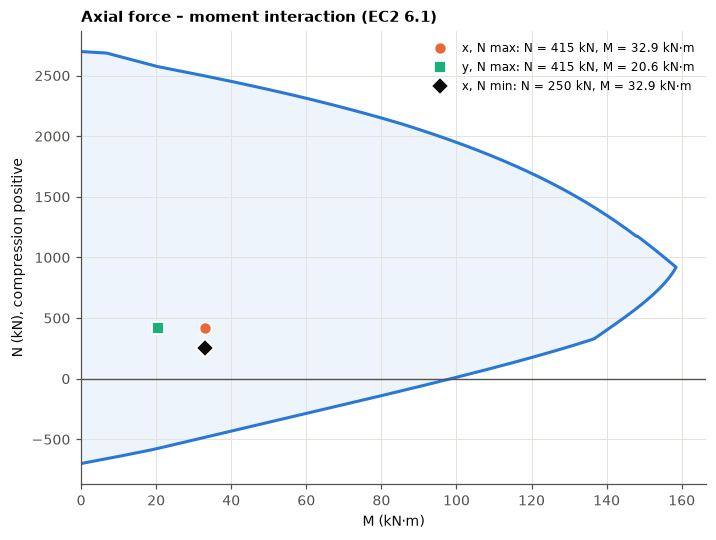

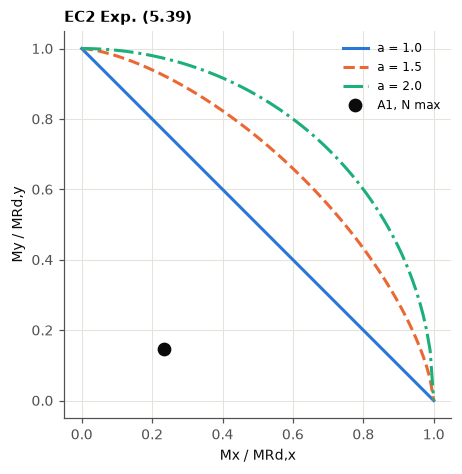

### Fire resistance (tabulated method B)

| Reference | Calculation | Output |
|:--|:--|:--|
|  | $N_{Ed}$ | $N_{Ed} = 414.7$ kN |
| EN 1992-1-2 5.3.3(3) Note 1 | $N_{0,fi} = 0.7\,N_{Ed}$<br>$\quad = 0.7\times 414.7$ | $\mathbf{N_{0,fi} = 290.3}$ kN |
| EN 1992-1-2 Exp. (5.8a) | $n_{fi} = \dfrac{N_{0,fi}\times 1000}{0.7\,\left(A_{c}\,f_{cd} + A_{s}\,f_{yd}\right)}$<br>$\quad = \dfrac{290.3\times 1000}{0.7\times \left(122500\times 17 + 1608.5\times 434.8\right)}$ | $\mathbf{n_{fi} = 0.149}$ |
| EN 1992-1-2 5.3.3(2) | $\omega = \dfrac{A_{s}\,f_{yd}}{A_{c}\,f_{cd}}$<br>$\quad = \dfrac{1608.5\times 434.8}{122500\times 17}$ | $\mathbf{\omega = 0.336}$ |
| EN 1992-1-2 Table 5.2b | **Check:** fire – tabulated row ω = 0.1 is conservative<br>$\omega = 0.336 \ge 0.1$  | ✅ **PASS**<br>ratio 0.30 |
|  | First-order eccentricity: $e_{fi}$ | $e_{fi} = 79.42$ mm |
| EN 1992-1-2 5.3.3(2) | min(0.25b, 100): $e_{max}$ | $e_{max} = 87.5$ mm |
| EN 1992-1-2 5.3.3(2) | **Check:** fire – method B eccentricity limit<br>$e_{fi} = 79.42 \le e_{max} = 87.5$ mm | ✅ **PASS**<br>ratio 0.91 |
| EN 1992-1-2 5.3.3(3) Note 2 | 0.5 × storey height: $l_{0,fi}$ | $l_{0,fi} = 1.75$ m |
| EN 1992-1-2 Exp. (5.8c) | $\lambda_{fi} = \dfrac{l_{0,fi}\times 1000}{i}$<br>$\quad = \dfrac{1.75\times 1000}{101}$ | $\mathbf{\lambda_{fi} = 17.32}$ |
| EN 1992-1-2 5.3.3(2) | **Check:** fire – method B slenderness limit<br>$\lambda_{fi} = 17.32 \le 30$  | ✅ **PASS**<br>ratio 0.58 |
| EN 1992-1-2 Table 5.2b | R 60, column n = 0.15, tabulated width 200 mm: $a_{req}$ | $a_{req} = 25$ mm |
|  | Axis distance: $a_{prov}$ | $a_{prov} = 41$ mm |
| EN 1992-1-2 5.3.3 | **Check:** fire – axis distance<br>$a_{prov} = 41 \ge a_{req} = 25$ mm | ✅ **PASS**<br>ratio 0.61 |


| Reference | Calculation | Output |
|:--|:--|:--|
| EN 1992-1-2 5.3.3 | Table 5.2b has no separate rule for biaxial bending; the larger eccentricity was used. A corner column with higher eccentricity needs a calculation method (EN 1992-1-2 Section 4 or Annex B). |  |


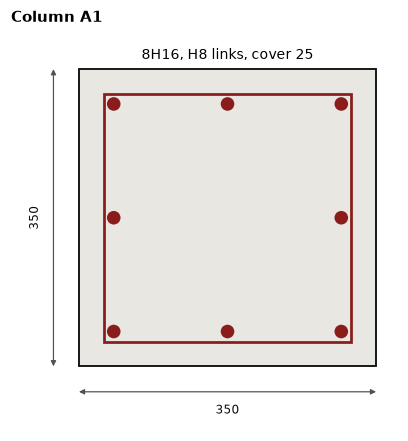

### Summary of checks

| Check | Reference | Ratio | Result |
|:--|:--|:-:|:--|
| nominal cover | EC2 4.4.1 | 1.00 | ✅ PASS |
| minimum bar diameter | EC2 9.5.2(1) | 0.75 | ✅ PASS |
| minimum steel | EC2 9.5.2(2) | 0.15 | ✅ PASS |
| maximum steel | EC2 9.5.2(3) | 0.33 | ✅ PASS |
| link diameter | EC2 9.5.3(1) | 0.75 | ✅ PASS |
| link spacing | EC2 9.5.3(3) | 0.94 | ✅ PASS |
| bar within 150 mm of a restrained bar, else add cross-ties | EC2 9.5.3(6) | 0.89 | ✅ PASS |
| biaxial bending, N_max | EC2 5.8.9 | 0.36 | ✅ PASS |
| biaxial bending, N_min | EC2 5.8.9 | 0.42 | ✅ PASS |
| fire – tabulated row ω = 0.1 is conservative | EN 1992-1-2 Table 5.2b | 0.30 | ✅ PASS |
| fire – method B eccentricity limit | EN 1992-1-2 5.3.3(2) | 0.91 | ✅ PASS |
| fire – method B slenderness limit | EN 1992-1-2 5.3.3(2) | 0.58 | ✅ PASS |
| fire – axis distance | EN 1992-1-2 5.3.3 | 0.61 | ✅ PASS |

**All checks pass.**

In [6]:
for lab, NN in (("N_max", N), ("N_min", Nmin)):
    s.let("N_Ed", NN, "kN", f"{lab}"); s.calc("N_Rd", "(A_c*f_cd + A_s*f_yd)/1000", "kN", "EC2 5.8.9(4)"); s.calc("r_N", "N_Ed/N_Rd"); s.let("a", max(1.0, C.biaxial_exponent(s["r_N"])), "", "Exponent", "EC2 5.8.9(4)"); s.let("M_Rd", C.MRd(cur, NN), "kN·m", "Resistance at this axial load", "EC2 6.1")
    s.calc("U_bi", "(M_Ed_x/M_Rd)**a + (M_Ed_y/M_Rd)**a", "", "EC2 Exp. (5.39)"); s.check("U_bi", "<=", 1.0, f"biaxial bending, {lab}", "EC2 5.8.9"); s.show(f"Axial load {lab}")
P.interaction_plot(cur, [("x, N max", N, Mx), ("y, N max", N, My), ("x, N min", Nmin, Mx)])
m = np.linspace(0, 1, 100); f, ax = plt.subplots(figsize=(4.6, 4.2))
for aa, col, ls in ((1.0, P.BLUE, "-"), (1.5, P.ORANGE, "--"), (2.0, P.AQUA, "-.")):
    ax.plot(m, (1 - m**aa) ** (1 / aa), color=col, ls=ls, lw=2, label=f"a = {aa}")
ax.plot(Mx / C.MRd(cur, N), My / C.MRd(cur, N), "o", color=P.INK, ms=8, label="A1, N max"); ax.set_xlabel("Mx / MRd,x"); ax.set_ylabel("My / MRd,y"); ax.set_aspect("equal"); ax.legend(fontsize=8); ax.set_title("EC2 Exp. (5.39)"); plt.show()
D.fire_column_b(s, BRIEF["fire"], b, s["d_c"], N, As, b * h, 0.5 * BRIEF["storey"], h / math.sqrt(12), M02x / N * 1e3)
s.note("Table 5.2b has no separate rule for biaxial bending; the larger eccentricity was used. A corner column with higher eccentricity needs a calculation method (EN 1992-1-2 Section 4 or Annex B).", "EN 1992-1-2 5.3.3"); s.show()
P.column_section(b, h, c, link, (3, 3), phi, "Column A1"); s.summary()